---
title: 2.6 Área, escala y población
short_title: 2.6 Área, escala y población
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/sincelejo/blob/main/book/02_datos/26_area_estudio.ipynb)

**Reproducible sin red en el checkout.** La fuente preservada y sus limitaciones se describen en el capítulo 2.3.


In [1]:
from pathlib import Path
import sys, subprocess
candidatos = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidatos if (p/'src/sincelejo/analisis.py').exists()), None)
if ROOT is None:
    ROOT = Path('/content/sincelejo')
    if not ROOT.exists():
        subprocess.run(['git','clone','https://github.com/mromerot/sincelejo.git',str(ROOT)],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','-e',str(ROOT)+'[libro]'],check=True)
sys.path.insert(0,str(ROOT/'src'))
from sincelejo.nb import *  # clima, anual, evidencia, ROOT, pd, plt, json, display, funciones

## Soporte espacial

El ámbito de gestión es el municipio 70001 y sus sistemas de servicio. La consulta climática es un punto regional; no se ha recortado una rejilla por el límite municipal. La siguiente figura muestra solo el punto y una escala angular alrededor, sin aparentar una cartografía de amenaza.

dias          12784
faltantes         0
duplicados        0
Name: Control de calidad, dtype: int64

Coordenadas solicitadas: [-75.3978, 9.3047]
SHA-256: e70bca9c901349fe936f9a7dc5907da53e1bc95a70877cb8aa3f15aa02eae9ab


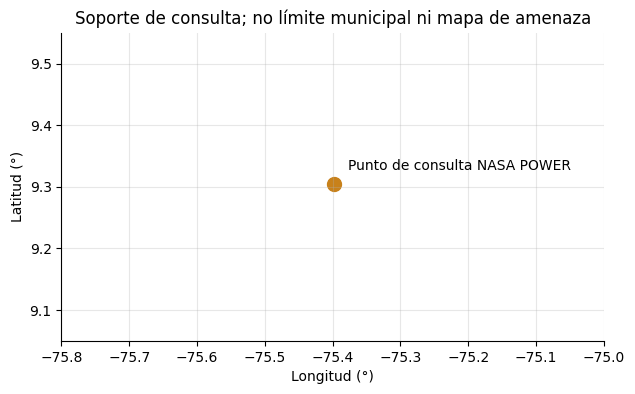

In [2]:
meta=json.loads((ROOT/'data/manifest.json').read_text())
display(pd.Series(meta['control_calidad'],name='Control de calidad'))
print('Coordenadas solicitadas:',meta['coordenadas_solicitadas'])
print('SHA-256:',meta['sha256'])
fig,ax=plt.subplots(figsize=(7,4)); ax.scatter([-75.3978],[9.3047],s=100,color='#c8811a'); ax.annotate('Punto de consulta NASA POWER',(-75.3978,9.3047),xytext=(10,10),textcoords='offset points'); ax.set(xlim=(-75.8,-75),ylim=(9.05,9.55),xlabel='Longitud (°)',ylabel='Latitud (°)',title='Soporte de consulta; no límite municipal ni mapa de amenaza'); ax.grid(alpha=.3); plt.show()

## Exposición demográfica de referencia

La ficha DANE reporta personas censadas, no una proyección actual ni personas expuestas a eventos. La cobertura geográfica de la cabecera difiere del soporte del producto climático. [@dane2018]

In [3]:
censo=json.loads((ROOT/'data/censo2018.json').read_text())
assert censo['cabecera']+censo['centros_poblados_rural_disperso']==censo['total']
display(pd.Series(censo,name='CNPV 2018'))
print('Proporción censada en cabecera: %.2f %%' % (100*censo['cabecera']/censo['total']))

fuente                                                                            dane2018
pagina                                                                                   1
universo                                 Personas efectivamente censadas CNPV 2018; no ...
total                                                                               274622
cabecera                                                                            248033
centros_poblados_rural_disperso                                                      26589
hogares_particulares                                                                 75407
viviendas_ocupadas_personas_presentes                                                74405
Name: CNPV 2018, dtype: object

Proporción censada en cabecera: 90.32 %


## Extensión espacial pendiente

Incorporar el límite oficial DANE con versión, microcuencas, perímetros urbanos y sectores de servicio. Registrar sistema de coordenadas y usar una proyección métrica apropiada para áreas y distancias. La precisión del dato de origen limita la interpretación, aunque se dibuje con más decimales.